# 62 · 선호 보상에서 RLHF 정책 갱신까지

과일의 요청 색을 한 단어로 답하고 끝내는 작은 token 환경을 만듭니다. 두 답변의 선호로 **보상 모델을 학습**한 다음, 실제로 답변을 샘플링하고 PPO로 정책을 바꿉니다. 같은 선호를 SFT·DPO로 사용한 결과도 함께 봅니다.

- 준비물: [45 token 정책](../06_언어모델/45_decoder_gpt.ipynb), [49 선호 쌍과 DPO](../06_언어모델/49_dpo.ipynb), [52 환경과 종료](52_mdp_bellman.ipynb), 56 정책 기울기·57 actor–critic·58 PPO입니다.
- 순서: ① 선호 reward 학습 → ② token 환경과 sequence 확률 → ③ reference KL과 return → ④ 고정 rollout PPO → ⑤ 실제 SFT/DPO/PPO 비교입니다.
- 범위: red/green/EOS의 작은 정책·reward·value MLP를 모두 처음부터 학습합니다. 사람 대신 명시적 합성 규칙으로 선호 라벨을 만듭니다. 따라서 사람 피드백의 질이나 실제 언어모델 안전성을 측정한 RLHF 실험은 아닙니다.

> **용어** · **RLHF**는 선호 같은 사람 피드백에서 학습한 보상으로 정책을 조정하는 흐름입니다. **reward model**은 prompt와 답변에 숫자 점수를 주는 모델입니다. **actor**는 token 행동 확률을, **critic/value**는 앞으로 받을 return의 평균을 예측합니다. **reference**는 처음 고정한 기준 정책, **old policy**는 해당 rollout을 수집한 정책입니다. 둘은 역할과 갱신 시점이 다릅니다.

### 읽는 법

| 표시 | 확인할 것 |
|---|---|
| 🔑 핵심 | 선호·보상·KL·정책 갱신 |
| 🔍 확인 | 미분·종료·정확 열거·생성 |
| 📎 참고 | 출처·축소 범위·관용구 |
| ✏️ 연습 | 핵심 한두 줄 구성 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 선호 보상을 배우는 목적과 그 보상을 높이는 정책 목적은 별개입니다.
2. reference는 전체 학습에서 고정하고 old log-prob·advantage는 한 rollout의 여러 epoch에서 고정합니다.
3. 학습 reward·독립 품질 규칙·KL·실제 생성 성공을 각각 확인합니다.

[그림 보조 코드](../../src/utils/rlhf_plots.py) · [학습 경로](../../docs/CURRICULUM.md)

In [1]:
import sys
from pathlib import Path
import numpy as np
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.rlhf_plots import (
    plot_reward_preference,plot_token_outcomes,plot_kl_rewards,plot_ppo_clip,
    plot_rlhf_budgets,plot_rlhf_learning,plot_policy_metrics,
)
setup_plots()

'Arial Unicode MS'

## 🔑 1. 선호 쌍으로 보상 모델을 먼저 학습합니다

**이 절에서 가져갈 것:** reward 모델은 절대 정답 점수 대신 두 답변의 점수 차이를 배웁니다.

빨강 요청에 `[red,EOS]`와 `[green,EOS]`가 왔다면 첫 답변을 더 선호합니다. prompt와 답변을 수치 특징 φ로 바꾸고 작은 MLP가 점수 $r_\psi$를 냅니다.

$$h=\tanh(\phi W+b),\quad r=hU+c,\quad L_{RM}=\operatorname{mean}\log(1+e^{-(r^+-r^-)})+\tfrac\rho2\|\psi\|^2.$$

φ:(N,12),W:(12,H),b:(H,),U:(H,1),c:(1,),H=12,ρ=.001입니다. φ는 fruit one-hot4, 요청 색2, 첫 token3, 둘째 token3을 이어 붙입니다. 답변이 EOS 하나면 둘째 token 특징은0입니다. 점수 차이는 표본마다 숫자 하나입니다.

$d=-(1-\sigma(r^+-r^-))/N$이면 chosen 상류는 d,rejected는−d입니다. MLP의 $dU=h^Tg$, $dc=\sum_ng$, $da=(gU^T)\odot(1-h^2)$, $dW=\phi^Tda$, $db=\sum_nda$, $d\phi=daW^T$를 양쪽 경로에서 더하고 L2 미분ρψ를 더합니다.

> **용어** · **Bradley–Terry 선호 모형**은 점수 차이를 sigmoid에 넣는 모형입니다. **L2**는 큰 파라미터에 제곱 벌점을 더하는 제약입니다. 출력에 공통 상수를 더하면 선호 확률은 같으며, L2를 제외한 pairwise 목적은 절대 기준점을 식별하지 못합니다. [선호 보상 원문](https://arxiv.org/abs/1706.03741)을 참고합니다.

In [2]:
reward_scores_hand=np.array([[1.,0.],[3.,2.],[-1.,1.]])
reward_differences_hand=reward_scores_hand[:,0]-reward_scores_hand[:,1]
reward_probabilities_hand=1/(1+np.exp(-reward_differences_hand))

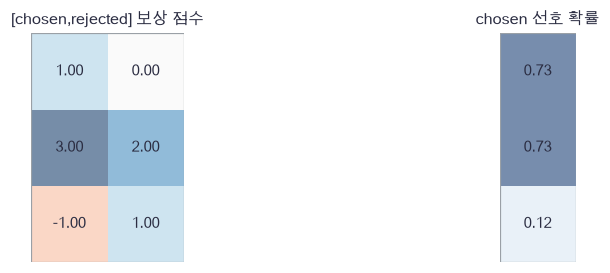

In [3]:
plot_reward_preference(reward_scores_hand,reward_probabilities_hand)

🔍 **확인** · 첫 두 쌍은 절대 점수가 다르지만 선호 확률은 같습니다. 보상을 사용할 때는 학습 데이터에서 정한 중심·척도를 고정해 정책의 KL 계수와 함께 기록합니다.

> **코드** · `np.logaddexp(0,-difference)`는 큰 점수에서도 안정한 선호 손실입니다. `parameters.items()`는 파라미터 이름·배열을 함께 순회합니다. `np.eye(K)[ids]`는 정수 ID를 one-hot 행으로 바꿉니다. `.copy()`는 서로 다른 모델의 배열을 분리합니다.

In [4]:
def init_network(inputs,hidden,outputs,seed):
    """입력→tanh→출력의 작은 공통 형태를 독립 파라미터로 초기화합니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.4/np.sqrt(inputs),(inputs,hidden)),
            'b':np.zeros(hidden),'U':rng.normal(0,.3/np.sqrt(hidden),(hidden,outputs)),
            'c':np.zeros(outputs)}

In [5]:
def network_forward(inputs,parameters):
    """작은 MLP의 출력과 전체 역전파에 필요한 입력·은닉값입니다."""
    hidden=np.tanh(inputs@parameters['W']+parameters['b'])
    return hidden@parameters['U']+parameters['c'],(inputs,hidden)

In [6]:
def network_backward(upstream,cache,parameters):
    """MLP의 모든 가중치·bias와 연속 입력 미분을 반환합니다."""
    inputs,hidden=cache
    dhidden=(upstream@parameters['U'].T)*(1-hidden**2)
    gradients={'U':hidden.T@upstream,'c':upstream.sum(axis=0),
               'W':inputs.T@dhidden,'b':dhidden.sum(axis=0)}
    return gradients,dhidden@parameters['W'].T

In [7]:
def log_softmax(logits):
    """마지막 행동 축의 안정한 log probability를 계산합니다."""
    shifted=logits-logits.max(axis=-1,keepdims=True)
    return shifted-np.log(np.exp(shifted).sum(axis=-1,keepdims=True))

In [8]:
def state_features(prompts,previous):
    """fruit4·요청 색2·이전 token3의 one-hot으로 상태 (N,9)를 만듭니다."""
    return np.concatenate([np.eye(4)[prompts[:,0]],np.eye(2)[prompts[:,1]],np.eye(3)[previous]],axis=1)

In [9]:
def outcome_features(prompts,responses):
    """prompt6과 첫/둘째 token3+3을 결합해 reward 입력 (N,12)를 만듭니다."""
    prompt_part=np.concatenate([np.eye(4)[prompts[:,0]],np.eye(2)[prompts[:,1]]],axis=1)
    token_part=np.zeros((len(responses),6))
    for row,response in enumerate(responses):
        token_part[row,response[0]]=1
        if len(response)==2:
            token_part[row,3+response[1]]=1
    return np.concatenate([prompt_part,token_part],axis=1)

In [10]:
def reward_pair_loss(chosen_features,rejected_features,parameters,regularization=.001):
    """BT 선호 CE와 작은 L2의 reward 모델 전체 미분입니다."""
    # 쓰는 것: network_backward, network_forward (앞 절의 정의·실행 셀)
    chosen,chosen_cache=network_forward(chosen_features,parameters)
    rejected,rejected_cache=network_forward(rejected_features,parameters)
    difference=chosen-rejected
    coefficient=-np.exp(-np.logaddexp(0.,difference))/len(chosen)
    plus,_=network_backward(coefficient,chosen_cache,parameters)
    minus,_=network_backward(-coefficient,rejected_cache,parameters)
    penalty=.5*regularization*sum((value**2).sum() for value in parameters.values())
    gradients={name:plus[name]+minus[name]+regularization*parameters[name] for name in parameters}
    return float(np.logaddexp(0.,-difference).mean()+penalty),gradients

In [11]:
def adam_state(p):
    """모든 학습 배열에 독립인 Adam 상태를 만듭니다."""
    return {'m':{name:np.zeros_like(value) for name,value in p.items()},
            'v':{name:np.zeros_like(value) for name,value in p.items()},'t':0}

In [12]:
def adam_update(p, gradients, state, learning_rate=.01):
    """Adam의 모멘트와 편향 보정으로 지정된 배열만 갱신합니다."""
    state['t'] += 1
    for name in gradients:
        state['m'][name] = .9*state['m'][name] + .1*gradients[name]
        state['v'][name] = .999*state['v'][name] + .001*gradients[name]**2
        first = state['m'][name]/(1-.9**state['t'])
        second = state['v'][name]/(1-.999**state['t'])
        p[name] -= learning_rate*first/(np.sqrt(second)+1e-8)

In [13]:
def check_reward_gradients():
    """reward MLP의 모든 파라미터를 고정 선호 특징에서 검산합니다."""
    # 쓰는 것: init_network (앞 절의 정의·실행 셀)
    rng=np.random.default_rng(6210)
    parameters=init_network(12,3,1,6210)
    chosen=rng.normal(0,.2,(3,12))
    rejected=rng.normal(0,.2,(3,12))
    _,gradients=reward_pair_loss(chosen,rejected,parameters)
    def objective():
        """선호 특징을 고정한 L2 포함 목적입니다."""
        return reward_pair_loss(chosen,rejected,parameters)[0]
    errors=[]
    for name,value in parameters.items():
        numeric=numerical_gradient(objective,value)
        np.testing.assert_allclose(gradients[name],numeric,atol=1e-8,rtol=1e-4)  # 검산: reward 전체 미분
        errors.append(np.max(np.abs(gradients[name]-numeric)))
    unshifted=reward_pair_loss(chosen,rejected,parameters,regularization=0)[0]
    parameters['c']+=7
    np.testing.assert_allclose(reward_pair_loss(chosen,rejected,parameters,regularization=0)[0],unshifted,atol=1e-12)  # 검산: L2 없는 선호 목적의 공통 점수 이동 불변
    return max(errors)

In [14]:
print('reward 전수 미분 최대오차:',check_reward_gradients())

reward 전수 미분 최대오차: 1.268229633723944e-10


### ✏️ 연습 1 · 선호 점수 차이

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

chosen과 rejected의 차이를 채우세요.

In [15]:
def exercise_rewarddiff(chosen, rejected):
    """선호 점수 차이의 계산을 완성합니다."""
    ### 구현할 내용: chosen과 rejected의 차이를 채우세요.
    raise NotImplementedError
    return difference

In [16]:
def check_rewarddiff(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([1.,8.]),np.array([0.,7.])),[1.,1.])  # 검산: 공통 이동 불변
    print("연습 1 통과")

run_check(check_rewarddiff, exercise_rewarddiff, hint="선호 점수 차이의 수식과 축을 확인하세요.")

☐ exercise_rewarddiff: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 선호 점수 차이의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
difference = chosen - rejected
```

</details>

## 🔑 2. 작은 token 환경을 끝까지 열거합니다

**이 절에서 가져갈 것:** 방문한 token의 확률을 곱해 전체 답변 확률을 만들고 종료를 구분합니다.

행동 ID0=red,1=green,2=EOS입니다. 상태는 fruit4·요청 색2·이전 token3의 one-hot `(N,9)`입니다. 이전 token의2는 시작 상태 BOS를 나타내며, 행동의EOS와 다른 역할입니다. 정책은 W:(9,8),U:(8,3)의 tanh MLP와 softmax입니다. attention이 없는 작은 정책이므로45번의 GPT를 재현하는 모델은 아닙니다.

EOS가 나오면 즉시 끝납니다. 그렇지 않으면 **두 token을 쓴 순간 환경 자체가 끝납니다.** 이 상한은 긴 episode를 임의로 잘라 수집한 것이 아닙니다. EOS 미종료도 결과로 채점하며 bootstrap을 하지 않습니다. 가능한 결과는 `[EOS]`, `[R,EOS]`, `[G,EOS]`, `[R,R]`, `[R,G]`, `[G,R]`, `[G,G]` 일곱 개입니다.

$$\pi(y\mid x)=\prod_{t=0}^{T(y)-1}\pi(a_t\mid s_t),\quad \ell(y)=\sum_t\log\pi(a_t\mid s_t).$$

종료 뒤 PAD 같은 가짜 행동은 추가하지 않습니다. 전체 일곱 확률의 합은1이어야 합니다. 아래 손계산에서 첫 행동EOS는.2이고 `[R,EOS]`는 .5×.8=.4입니다.

> **코드** · `np.add.at(totals,owners,selected)`는 각 답변의 token log-prob를 문서 번호별로 더합니다. `owners`는 펼친 token이 어느 episode에 속하는지 나타냅니다. `np.arange`는 각 행의 선택 행동 점수를 고르는 행 번호입니다.

In [17]:
conditional_probabilities_hand=np.array([[.5,.3,.2],[.1,.1,.8],[.2,.2,.6]])
sequence_probabilities_hand=np.array([.2,.5*.8,.3*.6,.5*.1,.5*.1,.3*.2,.3*.2])
outcome_names=['EOS','R EOS','G EOS','R R','R G','G R','G G']

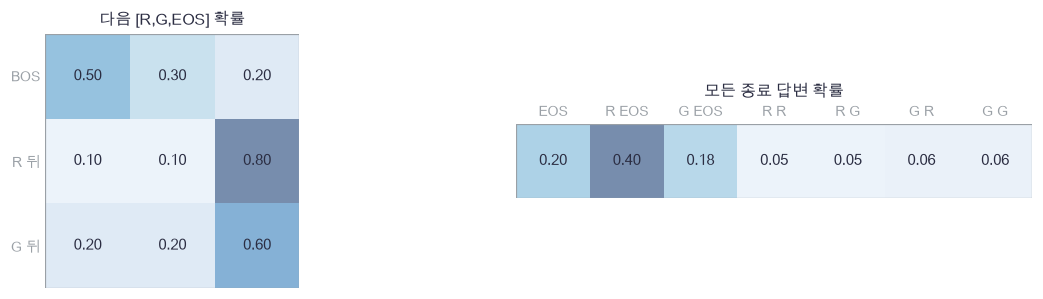

In [18]:
plot_token_outcomes(conditional_probabilities_hand,sequence_probabilities_hand,outcome_names)

🔍 **확인** · 한 token 종료와 두 token 종료를 같은 결과 공간에서 더합니다. 네 개의 상한 종료를 빼고 EOS 답변만 재정규화하면 다른 환경의 분포가 됩니다.

In [19]:
def enumerate_responses():
    """EOS 즉시 종료 또는 두 token 상한의 모든7개 결과를 반환합니다."""
    return [[2],[0,2],[1,2],[0,0],[0,1],[1,0],[1,1]]

In [20]:
def oracle_quality(prompt,response):
    """합성 선호 라벨 생성과 독립 평가에만 쓰는 명시적 채점 규칙입니다."""
    matched=float(response[0]==prompt[1])
    ended=float(response[-1]==2)
    return matched+.5*ended-.5*(len(response)==1)-.5*(1-ended)

In [21]:
def make_preferences(prompts):
    """동일 prompt의 모든 결과쌍 중 점수가 다른 쌍만 더 좋은 순서로 저장합니다."""
    prompt_rows,chosen,rejected=[],[],[]
    outcomes=enumerate_responses()
    for prompt in prompts:
        for left in range(len(outcomes)):
            for right in range(left+1,len(outcomes)):
                a,b=outcomes[left],outcomes[right]
                score_a,score_b=oracle_quality(prompt,a),oracle_quality(prompt,b)
                if score_a==score_b:
                    continue
                prompt_rows.append(prompt)
                chosen.append(a if score_a>score_b else b)
                rejected.append(b if score_a>score_b else a)
    return np.array(prompt_rows),chosen,rejected

In [22]:
def sequence_log_probability(prompts,responses,parameters):
    """실제 방문한 token 상태만 펼쳐 각 답변의 log probability를 합칩니다."""
    # 쓰는 것: log_softmax, network_forward, state_features (앞 절의 정의·실행 셀)
    owners,previous,actions=[],[],[]
    for row,response in enumerate(responses):
        assert 1<=len(response)<=2, '환경 답변 길이는1 또는2입니다'
        assert len(response)==2 or response[0]==2, '길이1 답변은 EOS로 끝나야 합니다'
        assert response[0]!=2 or len(response)==1, 'EOS 뒤 token은 없습니다'
        for time,action in enumerate(response):
            owners.append(row)
            previous.append(2 if time==0 else response[0])
            actions.append(action)
    owners,actions=np.array(owners),np.array(actions)
    features=state_features(prompts[owners],np.array(previous))
    logits,cache=network_forward(features,parameters)
    log_probs=log_softmax(logits)
    selected=log_probs[np.arange(len(actions)),actions]
    totals=np.zeros(len(responses))
    np.add.at(totals,owners,selected)
    return totals,(owners,actions,log_probs,cache)

In [23]:
def sequence_backward(coefficients,cache,parameters):
    """문서별 상류 미분을 각 방문 token의 onehot−prob로 전달합니다."""
    # 쓰는 것: network_backward (앞 절의 정의·실행 셀)
    owners,actions,log_probs,network_cache=cache
    delta=-np.exp(log_probs)
    delta[np.arange(len(actions)),actions]+=1
    delta*=coefficients[owners,None]
    return network_backward(delta,network_cache,parameters)

In [24]:
def supervised_loss(prompts,responses,parameters):
    """답변 sequence NLL을 문서별 평균하고 전체 정책을 미분합니다."""
    log_probability,cache=sequence_log_probability(prompts,responses,parameters)
    gradients,_=sequence_backward(-np.ones(len(responses))/len(responses),cache,parameters)
    return -log_probability.mean(),gradients

In [25]:
def train_supervised(initial,prompts,responses,steps=200):
    """동일 초기 정책의 사본에 정답 답변 SFT를 적용합니다."""
    # 쓰는 것: adam_state, adam_update (앞 절의 정의·실행 셀)
    parameters={name:value.copy() for name,value in initial.items()}
    state=adam_state(parameters)
    for _ in range(steps):
        _,gradients=supervised_loss(prompts,responses,parameters)
        adam_update(parameters,gradients,state,learning_rate=.02)
    return parameters

In [26]:
# 쓰는 것: conditional_probabilities_hand, sequence_probabilities_hand (앞 절의 정의·실행 셀)
probability_loop=[]
for answer in [[2],[0,2],[1,2],[0,0],[0,1],[1,0],[1,1]]:
    probability=conditional_probabilities_hand[0,answer[0]]
    if len(answer)==2:
        probability*=conditional_probabilities_hand[answer[0]+1,answer[1]]
    probability_loop.append(probability)
np.testing.assert_allclose(probability_loop,sequence_probabilities_hand)  # 검산: 손계산·반복문 경로 확률
np.testing.assert_allclose(sum(probability_loop),1.)  # 검산: 상한 종료 포함 전체 질량1
print('전체7경로 손계산·반복문 검산 통과')

전체7경로 손계산·반복문 검산 통과


In [27]:
def check_sequence_gradients():
    """길이1/2 답변의 합과 정책 전체 미분을 검산합니다."""
    # 쓰는 것: enumerate_responses, init_network, sequence_log_probability (앞 절의 정의·실행 셀)
    parameters=init_network(9,3,3,6213)
    prompts=np.array([[0,0],[1,1],[0,1]])
    responses=[[2],[1,2],[0,1]]
    _,gradients=supervised_loss(prompts,responses,parameters)
    def objective():
        """고정 답변의 문서 평균 NLL입니다."""
        return supervised_loss(prompts,responses,parameters)[0]
    for name,value in parameters.items():
        np.testing.assert_allclose(gradients[name],numerical_gradient(objective,value),atol=1e-8,rtol=1e-4)  # 검산: 모든 정책 배열 미분
    all_prompts=np.repeat(prompts[:1],7,axis=0)
    totals,cache=sequence_log_probability(all_prompts,enumerate_responses(),parameters)
    np.testing.assert_allclose(np.exp(totals).sum(),1.,atol=1e-12)  # 검산: 실제 정책 전체7답변 확률합1
    print('가변 길이 sequence 미분·질량 검산 통과')

In [28]:
check_sequence_gradients()

가변 길이 sequence 미분·질량 검산 통과


### ✏️ 연습 2 · sequence log probability

선택한 token의 log probability 합을 채우세요.

In [29]:
def exercise_seqsum(selected_log_probs):
    """sequence log probability의 계산을 완성합니다."""
    ### 구현할 내용: 선택한 token의 log probability 합을 채우세요.
    raise NotImplementedError
    return total

In [30]:
def check_seqsum(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(np.exp(candidate(np.log(np.array([.5,.8])))),.4)  # 검산: 합의 지수 = 경로확률 곱
    print("연습 2 통과")

run_check(check_seqsum, exercise_seqsum, hint="sequence log probability의 수식과 축을 확인하세요.")

☐ exercise_seqsum: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: sequence log probability의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = np.sum(selected_log_probs)
```

</details>

## 🔑 3. 고정 reference의 KL을 token 보상에 넣습니다

**이 절에서 가져갈 것:** 마지막 reward와 token별 KL shaping을 더하고, old policy와 reference를 구별합니다.

정책이 보상 점수만 높이려다 기존 행동에서 너무 멀어지지 않도록 기준 정책과의 KL을 함께 둡니다.

$$J(\theta)=E_{y\sim\pi_\theta}[\hat r_\psi(x,y)]-\lambda D_{KL}(\pi_\theta(\cdot|x)\|\pi_{ref}(\cdot|x)).$$

이번 λ=.2입니다. rollout은 현재 정책을 old로 저장한 상태에서 샘플링합니다. 방문한 각 token에 $k_t=\log\pi_{old}(a_t|s_t)-\log\pi_{ref}(a_t|s_t)$를 저장하고 $r_t=-\lambda k_t$로 둡니다. 마지막 token에만 학습한 전체 답변 보상 $\hat r_\psi$를 더합니다.

$$G_t=\sum_{u=t}^{T-1}r_u,\qquad A_t=G_t-V_{old}(s_t).$$

γ=1이며 MC return을 사용합니다. GAE·entropy bonus·advantage 정규화는 이 연결 예제에서 생략합니다. **KL의 한 표본 kₜ는 음수일 수 있지만, 전체 sequence KL의 기댓값은 음수가 아닙니다.** old의 보상·advantage는 이후 PPO epoch에서 다시 계산하지 않습니다. 이 고정 surrogate는 큰 정책 이동에서 원래 J와 같지 않습니다.

reward의 중심·척도는 모든 train prompt×7답변의 raw 점수에서만 정합니다. 이를 고정한 $\hat r=(r-\mu_{train})/(s_{train}+10^{-8})$를 사용합니다. reward 점수 단위가 바뀌면 λ의 상대 강도도 바뀝니다.

In [31]:
log_ratios_hand=np.log(np.array([1.2,.8]))
shaped_rewards_hand=-.2*log_ratios_hand
shaped_rewards_hand[-1]+=1.
returns_hand=np.cumsum(shaped_rewards_hand[::-1])[::-1]

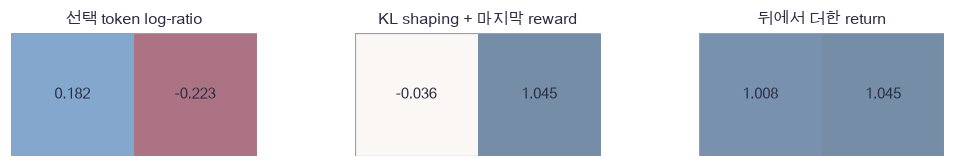

In [32]:
plot_kl_rewards(log_ratios_hand,shaped_rewards_hand,returns_hand)

🔍 **확인** · 둘째 token의 log-ratio는 음수라 KL shaping이 양수입니다. 이것만으로 정책 전체 KL이 음수라고 말할 수 없습니다. 전체 답변 확률로 가중합한 진단이 필요합니다.

> **코드** · `values[::-1]`은 역순으로 읽고 `np.cumsum`은 누적합을 구합니다. 역순 누적합 후 다시 뒤집으면 reward-to-go입니다. `rng.choice(3,p=probability)`는 실제 정책 확률로 행동을 뽑습니다. `rng.integers(N)`는 학습 prompt 번호 하나를 뽑습니다.

In [33]:
def reward_values(prompts,responses,parameters,center,scale):
    """고정 reward 모델의 점수를 train에서 정한 상수로만 정규화합니다."""
    # 쓰는 것: network_forward, outcome_features (앞 절의 정의·실행 셀)
    scores,_=network_forward(outcome_features(prompts,responses),parameters)
    return (scores[:,0]-center)/scale

In [34]:
def collect_token_rollout(policy,value_model,reference,reward_model,prompts,rng,center,scale,episodes=64,kl_coefficient=.2):
    """실제로 token을 샘플링하고 old 로그확률·value·보상·MC 타깃을 저장합니다."""
    # 쓰는 것: log_softmax, network_forward, state_features (앞 절의 정의·실행 셀)
    # 1. 방문한 token만 저장할 배열을 준비합니다.
    states,actions,old_logps,old_values,rewards,returns,episode_ids=[],[],[],[],[],[],[]
    for episode in range(episodes):
        prompt=prompts[rng.integers(len(prompts))]
        response,local_rewards=[],[]
        # 2. 수집 정책과 reference의 같은 행동 점수를 저장합니다.
        for time in range(2):
            previous=2 if time==0 else response[-1]
            features=state_features(prompt[None,:],np.array([previous]))
            logits,_=network_forward(features,policy)
            ref_logits,_=network_forward(features,reference)
            logp,ref_logp=log_softmax(logits)[0],log_softmax(ref_logits)[0]
            action=int(rng.choice(3,p=np.exp(logp)))
            old_value=network_forward(features,value_model)[0][0,0]
            states.append(features[0])
            actions.append(action)
            old_logps.append(logp[action])
            old_values.append(old_value)
            episode_ids.append(episode)
            response.append(action)
            local_rewards.append(-kl_coefficient*(logp[action]-ref_logp[action]))
            if action==2:
                break
        # 3. 종료 보상을 한 번 더하고 각 방문 시점의 return을 고정합니다.
        local_rewards[-1]+=reward_values(prompt[None,:],[response],reward_model,center,scale)[0]
        rewards.extend(local_rewards)
        returns.extend(np.cumsum(local_rewards[::-1])[::-1])
    old_values=np.array(old_values)
    return {'states':np.array(states),'actions':np.array(actions),'old_logp':np.array(old_logps),
            'old_values':old_values,'rewards':np.array(rewards),'returns':np.array(returns),
            'advantages':np.array(returns)-old_values,'owners':np.array(episode_ids),'episodes':episodes}

In [35]:
def exact_policy_metrics(parameters,reference,reward_model,prompts,center,scale):
    """7개 전체 답변을 열거해 sampling 오차 없는 정책 지표를 계산합니다."""
    # 쓰는 것: enumerate_responses, oracle_quality, sequence_log_probability (앞 절의 정의·실행 셀)
    outcomes=enumerate_responses()
    records=[]
    for prompt in prompts:
        repeated=np.repeat(prompt[None,:],7,axis=0)
        logp,_=sequence_log_probability(repeated,outcomes,parameters)
        logref,_=sequence_log_probability(repeated,outcomes,reference)
        probability=np.exp(logp)
        quality=np.array([oracle_quality(prompt,response) for response in outcomes])
        learned=reward_values(repeated,outcomes,reward_model,center,scale)
        exact=np.array([response==[int(prompt[1]),2] for response in outcomes])
        ended=np.array([response[-1]==2 for response in outcomes])
        records.append([probability@learned,probability@quality,probability@(logp-logref),probability@exact,probability@ended])
    return np.mean(records,axis=0)

In [36]:
# 쓰는 것: returns_hand, shaped_rewards_hand (앞 절의 정의·실행 셀)
returns_loop=np.zeros(2)
running=0.
for time in [1,0]:
    running+=shaped_rewards_hand[time]
    returns_loop[time]=running
np.testing.assert_allclose(returns_loop,returns_hand)  # 검산: return 반복문 = 역순 누적합
np.testing.assert_allclose(returns_hand[0],1-.2*np.log(1.2*.8))  # 검산: token log-ratio 합 = sequence log-ratio
print('KL shaping·return 손계산 통과')

KL shaping·return 손계산 통과


In [37]:
def check_exact_kl():
    """일곱 경로의 확률합·KL 비음수·token과 sequence log-ratio를 검산합니다."""
    # 쓰는 것: enumerate_responses, init_network, sequence_log_probability (앞 절의 정의·실행 셀)
    policy=init_network(9,4,3,6214)
    reference=init_network(9,4,3,6215)
    prompts=np.repeat(np.array([[0,1]]),7,axis=0)
    outcomes=enumerate_responses()
    current,current_cache=sequence_log_probability(prompts,outcomes,policy)
    fixed,fixed_cache=sequence_log_probability(prompts,outcomes,reference)
    owners,actions,logp,_=current_cache
    logref=fixed_cache[2]
    token_ratios=logp[np.arange(len(actions)),actions]-logref[np.arange(len(actions)),actions]
    summed=np.zeros(7)
    np.add.at(summed,owners,token_ratios)
    np.testing.assert_allclose(summed,current-fixed,atol=1e-12)  # 검산: token별 logratio 합 = sequence 차이
    probability=np.exp(current)
    np.testing.assert_allclose(probability.sum(),1.,atol=1e-12)  # 검산: 전체 확률합1
    assert probability@(current-fixed)>=-1e-12, '정확한 sequence KL은 음수가 아니어야 합니다'
    np.testing.assert_allclose(probability@(current-current),0.)  # 검산: 같은 정책 KL0
    print('정확한 경로 질량·KL·token 합 검산 통과')

In [38]:
check_exact_kl()

정확한 경로 질량·KL·token 합 검산 통과


### ✏️ 연습 3 · 마지막 보상 더하기

token KL 보상에 마지막 sequence reward를 더하세요.

In [39]:
def exercise_shaping(log_ratios, reward, coefficient):
    """마지막 보상 더하기의 계산을 완성합니다."""
    shaped = -coefficient * log_ratios.copy()
    ### 구현할 내용: token KL 보상에 마지막 sequence reward를 더하세요.
    raise NotImplementedError
    return shaped

In [40]:
def check_shaping(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([.5,-.2]),1.,.2),[-.1,1.04])  # 검산: terminal reward는 마지막에 한 번만
    print("연습 3 통과")

run_check(check_shaping, exercise_shaping, hint="마지막 보상 더하기의 수식과 축을 확인하세요.")

☐ exercise_shaping: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 마지막 보상 더하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
shaped[-1] += reward
```

</details>

## 🔑 4. rollout을 고정한 채 PPO를 여러 epoch 갱신합니다

**이 절에서 가져갈 것:** actor와 value를 별개 목적·분모로 미분하고, old 정보는 다시 만들지 않습니다.

수집한 답변을 한 번 학습한 다음 같은 token들로 한 번 더 학습합니다. 두 번째 epoch에서도 분모는 처음 수집한 old 확률입니다.

$$\rho_t(\theta)=e^{\log\pi_\theta(a_t|s_t)-\log\pi_{old}(a_t|s_t)},$$
$$L_\pi=-\frac1B\sum_{n,t}\min[\rho_{nt}A_{nt},\operatorname{clip}(\rho_{nt},1-\delta,1+\delta)A_{nt}],\quad\delta=.2.$$

B는 **episode 수**입니다. 길이1/2의 실제 token을 모두 더해 B로 나눕니다. A≥0이면 ρ>1+δ에서, A<0이면ρ<1−δ에서 surrogate의 미분이0입니다. 나머지에서는 $\partial L/\partial\log\pi=-A\rho/B$이고 logits에는 $(onehot(a)-p)$를 곱합니다. 경계점의 미분은 유일하지 않아0을 택하며 중심차분 검사는 경계를 피합니다.

value 모델 W:(9,8),U:(8,1)은 $L_V=\frac1{2M}\sum_t(V(s_t)-G_t)^2$를 최소화합니다. M은 실제 방문 token 수입니다. value 미분은 actor로 보내지 않고, actor 갱신 중 A·G도 고정합니다. MC의 이 목적은 실제 환경 종료를 기준으로 하므로 EOS/2token 상한 모두 bootstrap0입니다.

> **용어** · **surrogate**는 고정한 수집 배치를 재사용하기 위한 대리 목적입니다. **clip**은 특정 방향의 개선 유인을 멈추며 정책 이동이나 KL의 엄격한 상한을 보장하지 않습니다. [PPO 원문](https://arxiv.org/abs/1707.06347)과 연결됩니다.

In [41]:
ratio_hand=np.array([.6,1.,1.4])
advantage_hand=np.array([1.,-1.])[:,None]
unclipped_hand=advantage_hand*ratio_hand[None,:]
surrogate_hand=np.minimum(unclipped_hand,advantage_hand*np.clip(ratio_hand,.8,1.2)[None,:])

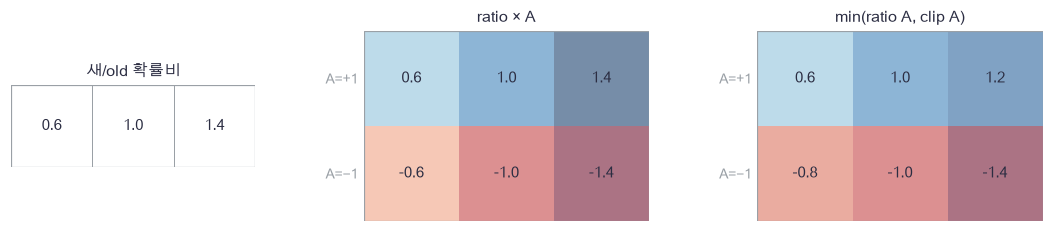

In [42]:
plot_ppo_clip(ratio_hand,unclipped_hand,surrogate_hand)

🔍 **확인** · A가 양수일 때 높은 비율의 유인을, 음수일 때 낮은 비율의 유인을 멈춥니다. 모든 비율을 무조건 clip한 뒤 미분하는 것과 다릅니다. 아래 검사에는 네 가지 부호·clip 조합을 모두 넣습니다.

In [43]:
def ppo_actor_loss(parameters,rollout,clip=.2):
    """고정 old logp·advantage를 쓰는 episode 평균 clipped surrogate입니다."""
    # 쓰는 것: log_softmax, network_backward, network_forward (앞 절의 정의·실행 셀)
    logits,cache=network_forward(rollout['states'],parameters)
    log_probs=log_softmax(logits)
    actions=rollout['actions']
    selected=log_probs[np.arange(len(actions)),actions]
    ratio=np.exp(selected-rollout['old_logp'])
    advantage=rollout['advantages']
    clipped=np.clip(ratio,1-clip,1+clip)
    loss=-np.minimum(ratio*advantage,clipped*advantage).sum()/rollout['episodes']
    active=np.where(advantage>=0,ratio<1+clip,ratio>1-clip)
    coefficient=-advantage*ratio*active/rollout['episodes']
    delta=-np.exp(log_probs)
    delta[np.arange(len(actions)),actions]+=1
    gradients,_=network_backward(delta*coefficient[:,None],cache,parameters)
    return loss,gradients,ratio

In [44]:
def value_loss(parameters,rollout):
    """고정 MC return을 valid token 수로 평균한 value MSE입니다."""
    # 쓰는 것: network_backward, network_forward (앞 절의 정의·실행 셀)
    values,cache=network_forward(rollout['states'],parameters)
    residual=values[:,0]-rollout['returns']
    gradients,_=network_backward(residual[:,None]/len(residual),cache,parameters)
    return .5*np.mean(residual**2),gradients

In [45]:
def train_ppo(initial,reward_model,prompts,valid_prompts,center,scale,seed,rounds=60):
    """새 rollout마다 old 정보를 저장하고 두 epoch 동안 actor/value를 분리 갱신합니다."""
    # 쓰는 것: adam_state, adam_update, collect_token_rollout, exact_policy_metrics, init_network (앞 절의 정의·실행 셀)
    parameters={name:value.copy() for name,value in initial.items()}
    value_model=init_network(9,8,1,6203)
    actor_state,value_state=adam_state(parameters),adam_state(value_model)
    rng=np.random.default_rng(seed)
    history=[]
    total_tokens=0
    for round_index in range(rounds+1):
        if round_index%15==0:
            metrics=exact_policy_metrics(parameters,initial,reward_model,valid_prompts,center,scale)
            history.append([round_index,*metrics])
        if round_index==rounds:
            break
        rollout=collect_token_rollout(parameters,value_model,initial,reward_model,prompts,rng,center,scale)
        total_tokens+=len(rollout['actions'])
        for _ in range(2):
            _,actor_gradients,_=ppo_actor_loss(parameters,rollout)
            _,value_gradients=value_loss(value_model,rollout)
            adam_update(parameters,actor_gradients,actor_state,learning_rate=.01)
            adam_update(value_model,value_gradients,value_state,learning_rate=.01)
    budget={'episodes':rounds*64,'sampled_tokens':total_tokens,'actor_updates':actor_state['t'],'value_updates':value_state['t']}
    return parameters,np.array(history),budget

In [46]:
def check_ppo_and_value_gradients():
    """clip 경계 밖 네 경우에서 actor와 value의 모든 배열을 검산합니다."""
    # 쓰는 것: init_network, log_softmax, network_forward (앞 절의 정의·실행 셀)
    rng=np.random.default_rng(6211)
    policy=init_network(9,3,3,6211)
    states=rng.normal(0,.2,(4,9))
    actions=np.array([0,1,2,1])
    logp=log_softmax(network_forward(states,policy)[0])
    rollout={'states':states,'actions':actions,'episodes':2,'returns':np.array([.1,.7,-.3,.4]),
             'old_logp':logp[np.arange(4),actions]-np.log([1.4,.6,1.4,.6]),'advantages':np.array([1.,1.,-1.,-1.])}
    _,gradients,_=ppo_actor_loss(policy,rollout)
    def actor_objective():
        """old logp와 advantage를 고정한 surrogate입니다."""
        return ppo_actor_loss(policy,rollout)[0]
    for name,value in policy.items():
        np.testing.assert_allclose(gradients[name],numerical_gradient(actor_objective,value),atol=1e-8,rtol=1e-4)  # 검산: PPO 전체 actor 미분
    critic=init_network(9,3,1,6212)
    _,value_gradients=value_loss(critic,rollout)
    def critic_objective():
        """return을 고정한 value MSE입니다."""
        return value_loss(critic,rollout)[0]
    for name,value in critic.items():
        np.testing.assert_allclose(value_gradients[name],numerical_gradient(critic_objective,value),atol=1e-8,rtol=1e-4)  # 검산: value 전체 미분
    print('positive/negative advantage·clip·value 전수 미분 통과')

In [47]:
check_ppo_and_value_gradients()

positive/negative advantage·clip·value 전수 미분 통과


### ✏️ 연습 4 · 유효 token value 평균

잔차에서 value loss를 채우세요.

In [48]:
def exercise_valueaverage(residual):
    """유효 token value 평균의 계산을 완성합니다."""
    ### 구현할 내용: 잔차에서 value loss를 채우세요.
    raise NotImplementedError
    return loss

In [49]:
def check_valueaverage(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,-2.,3.])),7/3)  # 검산: valid token3개 분모와1/2
    print("연습 4 통과")

run_check(check_valueaverage, exercise_valueaverage, hint="유효 token value 평균의 수식과 축을 확인하세요.")

☐ exercise_valueaverage: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 유효 token value 평균의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = .5 * np.mean(residual ** 2)
```

</details>

## 🔑 5. 실제 보상 학습·SFT·DPO·PPO를 연결해 비교합니다

**이 절에서 가져갈 것:** 같은 출발 정책에서도 목적·데이터 사용·seed·평가 지표를 분리합니다.

fruit0–1의 빨강/초록 요청4개를 train,fruit2의2개를 valid,fruit3의2개를 test로 둡니다. 새 과일 ID 조합에 대한 평가이며 색 두 개와 답변 어휘는 이미 보았습니다. 선호 라벨은 요청 색 일치+1,EOS종료+.5,즉시EOS−.5,EOS없는 상한종료−.5라는 합성 규칙으로 만듭니다. 동률은 선호 쌍에서 제외합니다. 정책은 이 점수 함수를 직접 받지 않고 RM은 선호 순서만 받습니다. 평가 때는 별도 oracle 품질로 다시 사용합니다.

1. 초기 정책을 항상 `[red,EOS]`라는 기존 답변으로30회 SFT해 reference를 만들고 고정합니다.
2. 68개 train 선호 쌍으로 reward MLP를300회 학습한 뒤 고정합니다. train prompt×7후보에서 점수 중심·척도를 정합니다.
3. 동일 reference 사본에서 SFT는 요청 색 정답4개를200회, DPO는68쌍을200회 학습합니다. Adam.02,DPO β=.5입니다.
4. PPO는 seed621/622/623에서 각각60rollout×64episode,rollout당2epoch,actor/value Adam.01로 학습합니다. λ=.2입니다. valid는 기록만 하고 test로 설정을 고르지 않습니다.

아래 데이터 단위는 SFT의 답변4개,DPO의 선호68쌍,PPO의 새 rollout3,840episode입니다. 방법별 정보·forward·gradient 예산이 달라 **보편적인 알고리즘 우열 실험이 아닙니다.** SFT/DPO는 전체배치를 쓰는 결정적 한 실행입니다. PPO만 샘플링 seed3개를 바꿉니다.

In [50]:
method_budgets=np.array([[4,200],[68,200],[60*64,60*2]])

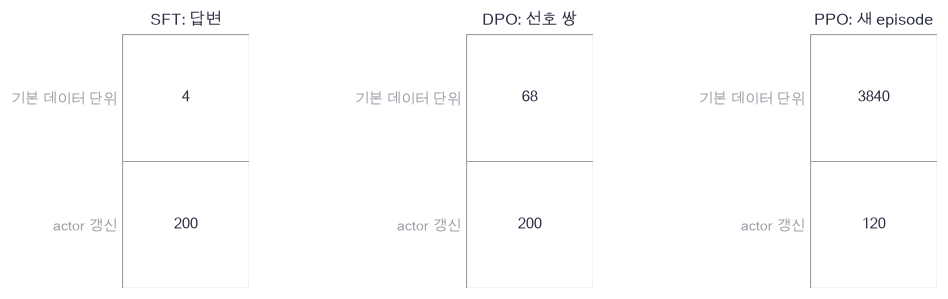

In [51]:
plot_rlhf_budgets(method_budgets,['SFT: 답변','DPO: 선호 쌍','PPO: 새 episode'])

🔍 **확인** · 같은 갱신 횟수만 맞춰도 사용한 답변 수가 같아지지는 않습니다. DPO는 한 쌍의 두 답변을 읽고, PPO는 길이가 다른 실제 token들을 샘플링합니다. 아래에서 PPO의 실제 token 수·actor/value 갱신 수도 출력합니다.

> **코드** · `np.repeat(prompts,7,axis=0)`는 각 prompt를 일곱 결과에 대응시킵니다. `responses * len(prompts)`는 결과 목록을 prompt 수만큼 반복합니다. `std(ddof=1)`은 세 학습 seed 사이의 표본 표준편차이며 MC 표준오차가 아닙니다.

In [52]:
def train_reward(preferences,steps=300):
    """고정 선호 쌍으로 reward MLP를 학습하고 optimizer를 분리합니다."""
    # 쓰는 것: adam_state, adam_update, init_network, outcome_features, reward_pair_loss (앞 절의 정의·실행 셀)
    prompts,chosen,rejected=preferences
    plus,outcome_minus=outcome_features(prompts,chosen),outcome_features(prompts,rejected)
    parameters=init_network(12,12,1,6201)
    state=adam_state(parameters)
    history=[]
    for step in range(steps+1):
        loss,gradients=reward_pair_loss(plus,outcome_minus,parameters)
        if step%100==0:
            history.append((step,loss))
        if step<steps:
            adam_update(parameters,gradients,state,learning_rate=.02)
    return parameters,np.array(history)

In [53]:
def dpo_policy_loss(preferences,parameters,reference_scores,beta=.5):
    """같은 고정 선호 쌍에서 sequence 합 기반 DPO의 전체 미분입니다."""
    # 쓰는 것: sequence_backward, sequence_log_probability (앞 절의 정의·실행 셀)
    prompts,chosen,rejected=preferences
    plus,plus_cache=sequence_log_probability(prompts,chosen,parameters)
    minus,minus_cache=sequence_log_probability(prompts,rejected,parameters)
    margin=beta*((plus-minus)-(reference_scores[0]-reference_scores[1]))
    coefficient=-beta*np.exp(-np.logaddexp(0.,margin))/len(plus)
    grad_plus,_=sequence_backward(coefficient,plus_cache,parameters)
    grad_minus,_=sequence_backward(-coefficient,minus_cache,parameters)
    return np.logaddexp(0.,-margin).mean(),{name:grad_plus[name]+grad_minus[name] for name in parameters}

In [54]:
def train_dpo(initial,preferences,steps=200):
    """reference 점수는 한 번만 계산하고 actor 사본만 갱신합니다."""
    # 쓰는 것: adam_state, adam_update, sequence_log_probability (앞 절의 정의·실행 셀)
    prompts,chosen,rejected=preferences
    references=[sequence_log_probability(prompts,responses,initial)[0].copy() for responses in [chosen,rejected]]
    parameters={name:value.copy() for name,value in initial.items()}
    state=adam_state(parameters)
    for _ in range(steps):
        _,gradients=dpo_policy_loss(preferences,parameters,references)
        adam_update(parameters,gradients,state,learning_rate=.02)
    return parameters

In [55]:
def generate_tokens(prompt,parameters):
    """정답 없이 token을 greedy로 내고 EOS 또는 환경 상한 종료를 반환합니다."""
    # 쓰는 것: network_forward, state_features (앞 절의 정의·실행 셀)
    response=[]
    for time in range(2):
        previous=2 if time==0 else response[-1]
        features=state_features(np.array([prompt]),np.array([previous]))
        logits,_=network_forward(features,parameters)
        response.append(int(logits[0].argmax()))
        if response[-1]==2:
            return response,'EOS'
    return response,'environment_limit'

In [56]:
# 쓰는 것: enumerate_responses, init_network, make_preferences, network_forward, outcome_features, train_reward, train_supervised (앞 절의 정의·실행 셀)
train_prompts=np.array([[fruit,color] for fruit in [0,1] for color in [0,1]])
valid_prompts=np.array([[2,0],[2,1]])
test_prompts=np.array([[3,0],[3,1]])
assert not {tuple(row) for row in train_prompts}&{tuple(row) for row in test_prompts}, 'train/test prompt는 겹치면 안 됩니다'
preferences=make_preferences(train_prompts)
assert len(preferences[0])==68, '고정 규칙의 train 선호 쌍은68개입니다'
reward_model,reward_history=train_reward(preferences)
reward_snapshot={name:value.copy() for name,value in reward_model.items()}
all_train_prompts=np.repeat(train_prompts,7,axis=0)
all_train_responses=enumerate_responses()*len(train_prompts)
train_scores=network_forward(outcome_features(all_train_prompts,all_train_responses),reward_model)[0][:,0]
reward_center,reward_scale=train_scores.mean(),train_scores.std()+1e-8
initial_policy=init_network(9,8,3,6202)
reference=train_supervised(initial_policy,train_prompts,[[0,2]]*len(train_prompts),steps=30)
reference_snapshot={name:value.copy() for name,value in reference.items()}
print('reward 중심·척도(train만):',reward_center,reward_scale)

reward 중심·척도(train만):

 -3.995596768422043 4.7850094383319695


In [57]:
# 쓰는 것: train_ppo, train_supervised (앞 절의 정의·실행 셀)
models={'reference':reference}
models['SFT']=train_supervised(reference,train_prompts,[[int(prompt[1]),2] for prompt in train_prompts])
models['DPO']=train_dpo(reference,preferences)
ppo_histories={}
ppo_budgets={}
for seed in [621,622,623]:
    name='PPO '+str(seed)
    models[name],ppo_histories[name],ppo_budgets[name]=train_ppo(reference,reward_model,train_prompts,valid_prompts,reward_center,reward_scale,seed)
    print(name,ppo_budgets[name])

PPO 621 {'episodes': 3840, 'sampled_tokens': 7657, 'actor_updates': 120, 'value_updates': 120}


PPO 622 {'episodes': 3840, 'sampled_tokens': 7660, 'actor_updates': 120, 'value_updates': 120}


PPO 623 {'episodes': 3840, 'sampled_tokens': 7661, 'actor_updates': 120, 'value_updates': 120}


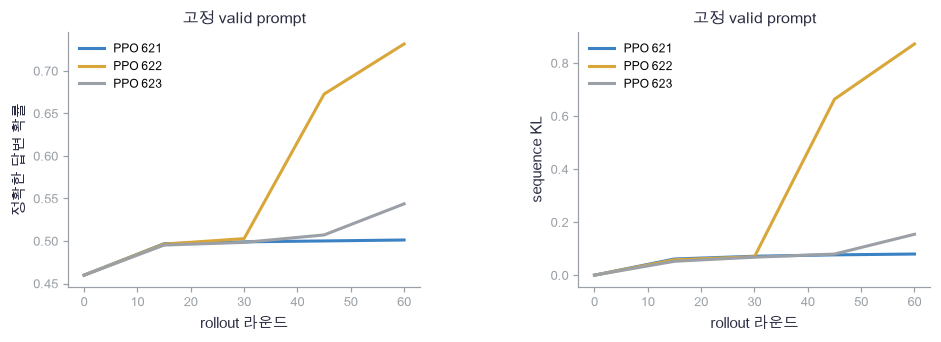

In [58]:
plot_rlhf_learning(list(ppo_histories.values()),list(ppo_histories))

🔍 **확인** · 왼쪽은 valid의 정확 답변 확률, 오른쪽은 같은 reference로부터의 정확한 sequence KL입니다. 세 seed는 정책 초기값·보상 모델·value 초기값이 같고 수집 행동 난수만 다릅니다. 학습 점수 상승만 보지 않고 두 축의 차이를 함께 읽습니다.

In [59]:
# 쓰는 것: exact_policy_metrics, make_preferences, reward_values (앞 절의 정의·실행 셀)
metrics=np.array([exact_policy_metrics(model,reference,reward_model,test_prompts,reward_center,reward_scale) for model in models.values()])
test_preferences=make_preferences(test_prompts)
reward_chosen=reward_values(test_preferences[0],test_preferences[1],reward_model,reward_center,reward_scale)
reward_rejected=reward_values(test_preferences[0],test_preferences[2],reward_model,reward_center,reward_scale)
print('test 선호 reward 순위 정확도:',np.mean(reward_chosen>reward_rejected))
print('PPO 3seed 지표 평균:',metrics[-3:].mean(axis=0))
print('PPO 3seed 지표 표준편차:',metrics[-3:].std(axis=0,ddof=1))

test 선호 reward 순위 정확도: 1.0
PPO 3seed 지표 평균: [1.29741444 1.1038182  0.39157638 0.60499851 0.99721559]
PPO 3seed 지표 표준편차: [0.09540139 0.13781943 0.47713457 0.1380418  0.00164496]


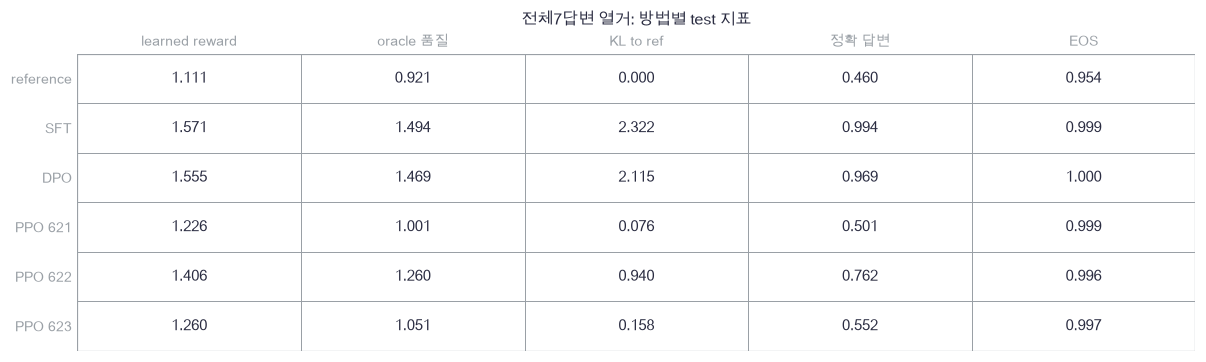

In [60]:
plot_policy_metrics(metrics,list(models))

🔍 **확인** · learned reward는 모델이 예측한 보상,oracle 품질은 별도 명시 규칙입니다. 두 값의 척도도 다릅니다. 정확 답변 확률과EOS 종료 확률도 다릅니다. 높은EOS 비율만으로 요청 색을 잘 맞혔다고 결론내리지 않습니다. 이 표는7답변 전체를 열거하므로 평가 sampling 오차가 없습니다. PPO행 사이 차이는 학습 중 샘플링 차이입니다.

In [61]:
# 쓰는 것: generate_tokens, models, reference, reference_snapshot, reward_model, reward_snapshot, test_prompts (앞 절의 정의·실행 셀)
for name,model in models.items():
    print(name)
    for prompt in test_prompts:
        response,reason=generate_tokens(prompt,model)
        expected=[int(prompt[1]),2]
        print(' prompt',prompt.tolist(),'생성',response,'종료',reason,'전체 일치',response==expected)
for name in reference:
    np.testing.assert_array_equal(reference[name],reference_snapshot[name])  # 검산: 모든 정책 학습 후 reference 완전 불변
for name in reward_model:
    np.testing.assert_array_equal(reward_model[name],reward_snapshot[name])  # 검산: PPO가 reward 파라미터를 갱신하지 않음
print('reference·reward 고정 검산 통과')

reference
 prompt [3, 0] 생성 [0, 2] 종료 EOS 전체 일치 True
 prompt [3, 1] 생성 [0, 2] 종료 EOS 전체 일치 False
SFT
 prompt [3, 0] 생성 [0, 2] 종료 EOS 전체 일치 True
 prompt [3, 1] 생성 [1, 2] 종료 EOS 전체 일치 True
DPO
 prompt [3, 0] 생성 [0, 2] 종료 EOS 전체 일치 True
 prompt [3, 1] 생성 [1, 2] 종료 EOS 전체 일치 True
PPO 621
 prompt [3, 0] 생성 [0, 2] 종료 EOS 전체 일치 True
 prompt [3, 1] 생성 [0, 2] 종료 EOS 전체 일치 False
PPO 622
 prompt [3, 0] 생성 [0, 2] 종료 EOS 전체 일치 True
 prompt [3, 1] 생성 [1, 2] 종료 EOS 전체 일치 True
PPO 623
 prompt [3, 0] 생성 [0, 2] 종료 EOS 전체 일치 True
 prompt [3, 1] 생성 [0, 2] 종료 EOS 전체 일치 False
reference·reward 고정 검산 통과


In [62]:
def check_dpo_and_rollout_boundaries():
    """DPO 전체 미분, rollout 고정 배열과 실제 종료 경계를 확인합니다."""
    # 쓰는 것: adam_state, adam_update, collect_token_rollout, dpo_policy_loss, generate_tokens, init_network, make_preferences, ppo_actor_loss, reward_center, reward_model, reward_scale, sequence_log_probability, train_prompts (앞 절의 정의·실행 셀)
    # 1. 고정 선호 쌍의 DPO 미분을 확인합니다.
    policy=init_network(9,3,3,6216)
    small_preferences=make_preferences(np.array([[0,0]]))
    prompts,chosen,rejected=small_preferences
    references=[sequence_log_probability(prompts,responses,policy)[0].copy() for responses in [chosen,rejected]]
    policy['c']+=np.array([.1,-.1,.2])
    _,gradients=dpo_policy_loss(small_preferences,policy,references)
    def objective():
        """고정 reference 점수와 선호 쌍의 DPO입니다."""
        return dpo_policy_loss(small_preferences,policy,references)[0]
    for name,value in policy.items():
        np.testing.assert_allclose(gradients[name],numerical_gradient(objective,value),atol=1e-8,rtol=1e-4)  # 검산: DPO 전체 정책 미분
    # 2. 갱신 뒤에도 old 정보가 고정되는지 확인합니다.
    critic=init_network(9,3,1,6217)
    rollout=collect_token_rollout(policy,critic,policy,reward_model,train_prompts,np.random.default_rng(6218),reward_center,reward_scale,episodes=8)
    fixed={name:rollout[name].copy() for name in ['old_logp','old_values','returns','advantages']}
    _,gradient,ratio=ppo_actor_loss(policy,rollout)
    np.testing.assert_allclose(ratio,1.,atol=1e-12)  # 검산: 수집 직후 new=old
    adam_update(policy,gradient,adam_state(policy),learning_rate=.01)
    _,_,new_ratio=ppo_actor_loss(policy,rollout)
    assert np.max(np.abs(new_ratio-1))>1e-8, '갱신 뒤 ratio는 고정 old와 비교해야 합니다'
    for name in fixed:
        np.testing.assert_array_equal(rollout[name],fixed[name])  # 검산: epoch 사이 old 정보·타깃 완전 고정
    # 3. 강제 행동으로 두 종류의 실제 종료를 확인합니다.
    policy['U'][:]=0
    policy['c'][:]=[0.,0.,1.]
    assert generate_tokens([0,0],policy)==([2],'EOS'), '즉시 EOS는1-step 종료입니다'
    policy['c'][:]=[1.,0.,0.]
    assert generate_tokens([0,0],policy)==([0,0],'environment_limit'), '두 token 미종료도 환경의 실제 끝입니다'
    print('DPO·old 고정·EOS·환경 상한 검산 통과')

In [63]:
check_dpo_and_rollout_boundaries()

DPO·old 고정·EOS·환경 상한 검산 통과


### ✏️ 연습 5 · 정확한 성공 확률

모든 답변 확률로 성공 여부를 가중합하세요.

In [64]:
def exercise_exactsucc(probabilities, successes):
    """정확한 성공 확률의 계산을 완성합니다."""
    ### 구현할 내용: 모든 답변 확률로 성공 여부를 가중합하세요.
    raise NotImplementedError
    return success_probability

In [65]:
def check_exactsucc(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([.2,.3,.5]),np.array([0,1,0])),.3)  # 검산: 성공 경로의 질량만 합
    print("연습 5 통과")

run_check(check_exactsucc, exercise_exactsucc, hint="정확한 성공 확률의 수식과 축을 확인하세요.")

☐ exercise_exactsucc: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정확한 성공 확률의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
success_probability = probabilities @ successes
```

</details>

## ✏️ 끝 연습 A–D

학습한 보상과 정책 갱신,token 축과episode 축,고정 기준을 다시 구분합니다.

### ✏️ 연습 A · sample KL shaping

token 로그확률 차이의 보상을 채우세요.

In [66]:
def exercise_tokenkl(old_logp, ref_logp, coefficient):
    """sample KL shaping의 계산을 완성합니다."""
    ### 구현할 내용: token 로그확률 차이의 보상을 채우세요.
    raise NotImplementedError
    return reward

In [67]:
def check_tokenkl(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([-1.,-3.]),np.array([-2.,-2.]),.2),[-.2,.2])  # 검산: 표본 KL 보상은 양·음 모두 가능
    print("연습 A 통과")

run_check(check_tokenkl, exercise_tokenkl, hint="sample KL shaping의 수식과 축을 확인하세요.")

☐ exercise_tokenkl: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: sample KL shaping의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
reward = -coefficient * (old_logp - ref_logp)
```

</details>

### ✏️ 연습 B · 고정 advantage

return과 old value의 차이를 채우세요.

In [68]:
def exercise_advantage(returns, old_values):
    """고정 advantage의 계산을 완성합니다."""
    ### 구현할 내용: return과 old value의 차이를 채우세요.
    raise NotImplementedError
    return advantage

In [69]:
def check_advantage(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([1.,2.]),np.array([.3,2.5])),[.7,-.5])  # 검산: baseline 차감
    print("연습 B 통과")

run_check(check_advantage, exercise_advantage, hint="고정 advantage의 수식과 축을 확인하세요.")

☐ exercise_advantage: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 고정 advantage의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
advantage = returns - old_values
```

</details>

### ✏️ 연습 C · episode 평균 surrogate

이미 선택된 surrogate token들을 B로 나누세요.

In [70]:
def exercise_episodeavg(surrogate, episodes):
    """episode 평균 surrogate의 계산을 완성합니다."""
    ### 구현할 내용: 이미 선택된 surrogate token들을 B로 나누세요.
    raise NotImplementedError
    return loss

In [71]:
def check_episodeavg(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,2.,3.]),2),-3.)  # 검산: token3개가 episode2개에 속함
    print("연습 C 통과")

run_check(check_episodeavg, exercise_episodeavg, hint="episode 평균 surrogate의 수식과 축을 확인하세요.")

☐ exercise_episodeavg: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: episode 평균 surrogate의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = -np.sum(surrogate) / episodes
```

</details>

### ✏️ 연습 D · 전체 sequence KL

일곱 답변의 정확한 KL을 채우세요.

In [72]:
def exercise_exactkl(logp, logref):
    """전체 sequence KL의 계산을 완성합니다."""
    ### 구현할 내용: 일곱 답변의 정확한 KL을 채우세요.
    raise NotImplementedError
    return kl

In [73]:
def check_exactkl(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.log(np.array([.5,.5])),np.log(np.array([.25,.75]))),.5*np.log(4/3))  # 검산: 전체 분포 KL
    print("연습 D 통과")

run_check(check_exactkl, exercise_exactkl, hint="전체 sequence KL의 수식과 축을 확인하세요.")

☐ exercise_exactkl: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 전체 sequence KL의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
kl = np.exp(logp) @ (logp - logref)
```

</details>

## ✏️ 준비도 확인

- **설명:** reward 모델 학습과 SFT·DPO·PPO 정책 학습이 받는 피드백을 구분할 수 있나요?
- **수식:** sequence log-ratio를 token 합으로 쓰고,actor의episode 평균과critic의token 평균을 구분할 수 있나요?
- **구현:** reference·reward를 고정하고 old log-prob·return·advantage를 여러epoch 동안 보존할 수 있나요?
- **변형 검산:** 즉시EOS·상한종료·clip양쪽·학습seed·reward척도를 바꾸며 불변과 변화의 범위를 확인할 수 있나요?

## 📎 참고와 한계

[선호 보상 학습](https://arxiv.org/abs/1706.03741), [PPO](https://arxiv.org/abs/1707.06347), [InstructGPT](https://arxiv.org/abs/2203.02155), [DPO](https://arxiv.org/abs/2305.18290)가 각각 선호→보상,rollout→정책 갱신,언어모델의 SFT/RLHF 흐름,직접 선호 목적을 연결합니다. 이번 실험은 사람 대신 합성 선호를 쓰고 작은 one-hot 상태 MLP를 사용합니다. 대규모 언어모델·자연어 reward·사람 평가를 재현하지 않습니다.

보상 순위가 정확해도 초기 정책에서 좋은 행동을 드물게 뽑으면 PPO 개선은 seed에 민감할 수 있습니다. 그 가능성을 실제 세 seed와 자유 생성으로 읽습니다. 신뢰할 수 있는 정책 평가에는 더 많은 과제·라벨·seed가 필요하며, 여기서는 미분과 데이터 흐름의 완성된 작은 경로만 확인했습니다.